## ME 125/225 CV, Fall 2026
# Homework 2

**Due on Gradescope:** 10/28/2026 at 11:59pm

**Submission Instructions:**

*   Make a copy of this Colab notebook in your drive. (File -> Save a copy in Drive)
*   Complete your homework by writing code in your copy of the notebook and writing answers to the written questions.
* When you are ready to submit, run all your cells so the outputs show in this notebook.
* Save your colab notebook as a PDF. (File -> Print -> Save as PDF).
* If required, combine the colab PDF with a PDF of any written answers.
* Submit two files on Gradescope:
  * Combined PDF of Colab and written answers
  * Python notebook of Colab (File -> Download -> Download .ipynb)

***
**Submission Specifications:**
To earn a 2/2 (Satisfactory) on this submission, you must meet every spec listed:

*General specs:*

☐ G1: Your notebook runs cleanly top to bottom, without errors.

☐ G2: You submit both the notebook (.ipynb) and a PDF. The PDF shows all code, printed outputs, and plots, with nothing cut off.

*Q1 (CFTOC) specs:*

☐ 1.1: All plots are included.

☐ 1.2: All constraints are implemented, and the cost function is encoded correctly.

☐ 1.3: Analysis questions are answered thoughtfully.


*Q2 (Dynamic Programming by hand) specs:*

☐ 2.1: Correct approach for calculating $c(g)$ based on work shown, using worst-case disturbance $w$.

☐ 2.2: Dynamic programming recursion algorithm implemented correctly using $c(g)$.

☐ 2.3: Effectively shows that no robust feasible open-loop schedule exists.

*Q3 (Dynamic Programming in code) specs:*

☐ 3.1: Cost $c(g)$ is calculated correctly (fine to re-use code from earlier Colab)

☐ 3.2: Resulting plot of $c(g)$ is piecewise linear, with jumps when new plants switch on.

☐ 3.3: Dynamic programming algorithm is initialized with the correct terminal cost.

☐ 3.4: Dynamic programming algorithm considers worst-case $w$, with possible $g$ rejected if any allowable $w$ would violate demand constraints.

☐ 3.5: Dynamic programming algorithm selects optimal $g$ with lowest worst-case cost-to-go.

☐ 3.6: Resulting policy plot looks believable.

*Q4 (Maze!!) specs:*

☐ 4.1: The dynamics function $f$ does not move into walls

☐ 4.2: The terminal cost function is implemented correctly

☐ 4.3: The stage cost function is implemented correctly

☐ 4.4: The dynamic programming algorithm is implemented correctly.

☐ 4.5: Analysis questions are answered thoughtfully.



***
If you are enrolled in ME 125/225 CV, you may take notes and make copies of course materials for your own use. You may also share those materials with another student who is registered and enrolled in this course, and with DSP. You may not reproduce, distribute or display course materials in any other way — whether or not a fee is charged — without my express written consent. You also may not allow others to do so. **You may not upload any course files to generative AI models.**

***

In [ ]:
!pip install -q pyomo
!apt-get install -y -qq glpk-utils           # GLPK: a useful solver for LPs and MILPs
!pip install -q idaes-pse                    # Provides the 'idaes get-extensions' helper, which gets solvers
!idaes get-extensions --to ./bin             # Downloads Ipopt (and CBC) into ./bin. These are useful solvers for QPs.

import os
os.environ["PATH"] = os.path.abspath("bin") + os.pathsep + os.environ["PATH"]

import pyomo.environ as pyo

import numpy as np
import matplotlib.pyplot as plt
from pyomo.opt import TerminationCondition

Getting files...
Done
-----------------------------------------------------------------
IDAES Extensions Build Versions
Solvers:  v3.4.2 20240811 ubuntu2204-x86_64
Library:  v3.4.2 20240811 ubuntu2204-x86_64



# Question 1: Constrained Finite-Time Optimal Control of a Vehicle

In this question, we will consider a nonlinear finite-time optimal control problem for a simplified kinematic bicycle model. Collect the states in one vector as $z = [x, y, v, \psi]^T$ and the inputs as $u = [a, \beta]^T$, where

\begin{align}
x &= \text{ global x center of gravity (CoG) coordinate} \nonumber \\
y &= \text{ global y CoG coordinate} \nonumber \\
v &= \text{ speed of the vehicle} \nonumber \\
\psi &= \text{ global heading angle} \nonumber \\
a &= \text{ acceleration of the CoG (along direction of velocity)} \nonumber \\
\beta &= \text{ angle of the current velocity with respect to the longitudinal axis of the car} \nonumber \\
l_r &= \text{ distance from the CoG of the vehicle to the rear axle} \nonumber
\end{align}

Using Forward Euler discretization with sampling time $\Delta t = 0.2$, the discrete-time model is

\begin{align}
x_{k+1} &= x_k + \Delta t \, v_k \cos(\psi_k + \beta_k) \nonumber\\
y_{k+1} &= y_k + \Delta t \, v_k \sin(\psi_k + \beta_k) \nonumber\\
v_{k+1} &= v_k + \Delta t \, a_k \nonumber\\
\psi_{k+1} &= \psi_k + \Delta t \, \frac{v_k}{l_r} \sin(\beta_k) \nonumber
\end{align}

which we write compactly as $z_{k+1} = z_k + f(z_k, u_k)\Delta t$. Use $l_r = 1.738$ m. (The front steering angle can be recovered from $\beta$ as $\delta_f = \tan^{-1}\left(\frac{l_f + l_r}{l_r}\tan\beta\right)$, with $l_f = 1.738$ m.)

You are asked to formulate and solve a parking problem as a finite-time optimal control problem. The vehicle starts from the initial state $\bar{z}_0 = [0, 3, 0, 0]^T$. Our goal is to park the vehicle in the terminal state $\bar{z}_N = [0, 0, 0, -\pi/2]^T$. Set the horizon $N = 70$ and the state constraints to be

$z_{min} := [-20, \hspace{2.5mm}-5,\hspace{2.5mm}-10, \hspace{2.5mm}-2\pi]^T \leq z_k \leq [20, \hspace{2.5mm}10,\hspace{2.5mm}10, \hspace{2.5mm}2\pi]^T =: z_{max}$.

We formulate the constrained finite-time optimal control problem (CFTOCP) defined below:

\begin{align}
\min_{z_0,\ldots,z_N,u_0,\ldots,u_{N-1}} & \sum_{k=N-2}^{N} \|z_k - \bar{z}_N \|_2^2 \nonumber\\
\text{s.t. } & z_{k+1} = z_k + f(z_k,u_k)\Delta t &&~\forall k = \{0,\ldots,N-1\} \nonumber\\
& z_{min} \leq z_k \leq z_{max} &&~\forall k = \{0,\ldots,N\} \nonumber\\
& u_{min} \leq u_k \leq u_{max} &&~\forall k = \{0,\ldots,N-1\} \nonumber\\
& | \beta_{k+1} - \beta_k | \leq \beta_{d} &&~\forall k = \{0,\ldots,N-2\} \nonumber\\
& | a_{k+1} - a_k | \leq a_{d} &&~\forall k = \{0,\ldots,N-2\} \nonumber\\
& z_0 = \bar{z}_0 \nonumber\\
& z_N = \bar{z}_N \nonumber
\end{align}

where the input constraints are defined as follows:

*   The accelerations are bounded by $|a_k| \leq 0.3$ m/s$^2$.
*   The steering control inputs are limited to $|\beta_k| \leq 0.6$ rad.
*   The difference between consecutive steering commands is bounded by $\beta_d = 0.2$ rad.
*   The difference between consecutive acceleration commands is bounded by $a_d = 0.06$ m/s$^2$. This constraint produces a smoother parking maneuver.


**Part (a)**

Solve the CFTOC (I recommend IPOPT here) and plot the following results:
1. The vehicle trajectory ($y_k$ vs. $x_k$)
2. Each of the 4 states vs. time (one figure with 4 subplots)
3. Each of the 2 inputs vs. time (one figure with 2 subplots)


In [ ]:
# Add your code here


**Part (b)**

Answer the following questions:
1. Is this problem convex? Why/why not?  
2. Are the acceleration rate constraints important to include?

1. This problem is not convex! The equality constraint from the dynamics is not affine.
2. Yes, the acceleration rate constraints are important! Without them, the vehicle switches between accelerating and decelerating much quicker (and the resulting optimal control cost is lower).

# Question 2: Dynamic Programming by hand (one time only ever, I promise)

Earlier in class we solved a power plant scheduling problem as an (open-loop) optimal control problem: we chose the entire 24-hour schedule up front, assuming our demand forecast was exactly correct. We will revisit this problem in this assignment with two changes:

1. We will make the demand **uncertain**: at each time step $k$, the realized demand may be up to some $\Delta$ kW above or below the demand forecast $\bar{d}_k$ (in this problem, $\Delta = 1$).
2. We will add a **storage buffer** (a battery) where we can store generated power we did not immediately use to satisfy current demand. The energy stored in the battery at time step $k$ is denoted $s_k$, and is the state of the system. If the demand at time step $k$ is greater than the power generated by our three plants at time step $k$, we can meet demand by drawing stored energy from the battery.

We will see that no open-loop schedule that we fix in advance can promise to satisfy the (uncertain!) demand over the planning horizon, while a closed-loop policy can.

*(We will do a small version of the problem first to go through dynamic programming step by step, before coding it for a larger version of the problem next. Working through dynamic programming by hand first makes it clear how the recursion runs backward and how the optimal decision at each time depends on the state, making the policy closed-loop.)*

Consider three power generating plants of different types (e.g. nuclear, hydro, gas, oil, or coal). When on, each plant $i$ has a power capacity in the range $[P_i^{min},~ P_i^{max}]$. When off, a plant produces no power. The cost of running plant $i$ for one hour is given by $C_iP_i$, where $P_i$ is the power currently being produced by plant $i$.

| Plant # | Cost $C$, in \$/kWh | $P^{min}$, in kW | $P^{max}$, in kW|
| :---: | :---: | :---: | :---: |
| 1 | 10 | 2 | 4 |
| 2 | 20 | 4 | 5 |
| 3 | 20 | 1 | 2 |

The demand forecast at time step $k$ is given by $\bar{d}_k$. In this problem (so you can do it by hand), we will consider a horizon of only two hours $(T=2)$. Our forecasted demand is given by $\bar{d}_0 = 3$ and $\bar{d}_1 = 6$. The uncertainty in the demand at any time step $k$ is given by $w_k \in \{-1, 0, 1\}$ kW. This means the true demand at time step $0$ could be anywhere in $\{2, 3, 4 \}$ kW.

Each time step is one hour. $s_k$ is the energy (in kWh) stored in the battery at the *start* of hour $k$. During hour $k$, the plants generate $g_k$ and the demand $\bar{d}_k + w_k$ is consumed, so $s_{k+1}$ is the charge at the *end* of hour $k$ (equivalently, the start of hour $k+1$). The generation $g_k$ is chosen at the start of hour $k$, after observing $s_k$ but *before* the demand deviation $w_k$ is revealed.

The storage state (how much energy we have stored in our battery) evolves as
$$s_{k+1} = s_k + g_k - \bar{d}_k - w_k$$
where $g_k$ is the total power generated across all three plants during hour $k$. Based on the $P^{min}$ and $P^{max}$ values, $g_k$ can take any integer value in $\{0, 1, \dots, 11\}$; in this problem we restrict $g_k$ to these integer values.

Our battery capacity imposes the constraint
$$0 \leq s_k \leq 4.$$
Excess power cannot be thrown away: any generation that is not consumed goes into the battery, so we may not produce so much that the battery would exceed its capacity. The battery starts at $s_0 = s_{\text{init}} = 1$, and it must end the task with at least as much charge as it started with, i.e. $s_2 \geq s_{\text{init}}$.

Because the demand is uncertain, a choice of $g_k$ is only feasible if these constraints hold for every possible realization $w_k \in \{-1, 0, 1\}$.

Our task is to determine

*   how much power to produce with our (up to) three plants at $k=0$ and $k=1$
*   in order to be able to meet the uncertain demand
*   while minimizing the cost associated with power production.

Specifically, you will determine a *feedback policy* $g_k(s_k)$ for $k=0$ and $k=1$ that selects how much power to produce at each time step based on the current battery charge (and the uncertain future demand).

Mathematically, we will implement the "minimax" Bellman recursion:

\begin{align}
J_k^*(s_k) = \min_{g_k \in \{0, 1, \dots, 11\}} \max_{w_k \in \{-1,0,1\} } & ~c(g_k) + J_{k+1}^*(s_{k+1})\\
\mathrm{s.t.}~~ & s_{k+1} = s_k+g_k-\bar{d}_k-w_k \\
& 0 \leq s_{k+1} \leq 4 \quad \text{for all } w_k \in \{-1,0,1\}
\end{align}

where $c(g)$ is the minimum cost to produce exactly $g$ kW with the three plants (for example, $g = 4$ can be produced by plant 1 alone or by plant 2 alone; $c(4)$ is the cheaper of the two). This policy minimizes the worst-case total cost. You can initialize your recursion with the terminal cost $J_T(s_T)$:
$$
J_T(s_T) = \begin{cases} 0, \quad s_T \geq s_{\text{init}} \\
+ \infty, \quad \text{otherwise.} \end{cases}
$$

**Part (a)**

Use the Dynamic Programming approach to compute the closed-loop optimal policy for the problem (please show your work). Your solution should fill in the $\dots$ in the following:
\begin{align*}
J_{2 \rightarrow 2}^*(s_2) &= \begin{cases} 0, \quad s_2 \geq s_{\text{init}} \\
+ \infty, \quad \text{otherwise} \end{cases} \\
J_{1 \rightarrow 2}^*(s_1) &= \begin{cases} \dots, \quad s_1 = 0 \\
\dots, \quad s_1 = 1 \\
\dots, \quad s_1 = 2 \\
\dots, \quad s_1 = 3 \\
\dots, \quad s_1 = 4 \\
\end{cases}\\
g_1^*(s_1) &= \begin{cases} \dots, \quad s_1 = 0 \\
\dots, \quad s_1 = 1 \\
\dots, \quad s_1 = 2 \\
\dots, \quad s_1 = 3 \\
\dots, \quad s_1 = 4 \\
\end{cases} \\
J_{0 \rightarrow 2}^*(s_{\text{init}}) &= \dots \\
g_0^*(s_{\text{init}}) &= \dots
\end{align*}

Feel free to re-use the previous MILP code to calculate $c(g)$, but this is also straightforward to calculate by hand.

**Part (b)**

Show that no open-loop solution (i.e. fixed values of $g_0$ and $g_1$) satisfies the constraints under demand uncertainty.

# Question 3: Dynamic Programming in code

We will now consider the power system problem but over a 24 hour cycle ($T = 24$). Note that in addition to the task horizon $T$ changing, we also change the power plant, battery, and demand for this problem. The table below contains the cost in per kWh, $P^{\text{min}}$, and $P^{\text{max}}$ for each of the three plants.

| Plant # | Cost $C$, in \$/kWh | $P^{min}$, in kW | $P^{max}$, in kW|
| :---: | :---: | :---: | :---: |
| 1 | 10 | 20 | 100 |
| 2 | 20 | 40 | 50 |
| 3 | 20 | 1 | 25 |

The nominal demand at time step $k$ denoted $\bar{d}_k$ is now defined by the periodic function:
$$
\bar{d}_k = \operatorname{round}(100 + 50 \sin{\frac{2 \pi k}{T}})
$$
where $\operatorname{round}(\cdot)$ rounds to the nearest integer. The uncertainty in the demand at time step $k$ is given by $w_k \in \{-10, 0, 10\}$.

Our storage battery has capacity $S = 80$ and is initialized at $s_0 = s_{\text{init}} = 40$. Hence we must satisfy the constraint: $0 \leq s_k \leq 80, \: \forall k = 0, \dots, T$. We must complete the 24 hour cycle ending with at least as much charge as we started with, $s_T \geq s_{\text{init}}$.

Based on the plant parameters, at a given time step $k$ we can produce $g_k \in \{0, \dots, 175\}$ kW (integers only) of power.

Exactly like the prior problem, our task is to determine

*   how much power to produce with our (up to) three plants
*   in order to be able to meet the uncertain demand
*   while minimizing the cost associated with power production.

Specifically, you will determine a *feedback policy* $g_k(s_k)$ for $k=0, \dots, T-1$ that selects how much power to produce at each time step based on the current battery charge (and uncertain future demand).

Mathematically, we will implement the **minimax** Bellman recursion:

\begin{align}
J_k^*(s_k) = \min_{g_k} \max_{w_k \in \{-10,0,10\} } & c(g_k) + J_{k+1}^*(s_{k+1})\\
\mathrm{s.t.}~~ & s_{k+1} = s_k+g_k-\bar{d}_k-w_k \\
& 0 \leq s_{k+1} \leq 80 \quad \text{for all } w_k \in \{-1,0,1\}\\
& 0 \leq g_k \leq 175
\end{align}
where the cost $c(g)$ is the optimal cost to produce exactly $g$ units of power with the three plants. This policy minimizes the **worst-case** total cost. You can initialize your recursion with the terminal cost $J_T(s_T)$:
$$
J_T(s_T) = \begin{cases} 0, \quad s_T \geq s_{\text{init}} \\
+ \infty, \quad \text{otherwise.} \end{cases}
$$



In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# problem parameters
T = 24

n_plants = 3
plant_cost = [10, 20, 20]      # $ per kW produced
plant_pmin = [20, 40,  1]      # kW, minimum output when on
plant_pmax = [100, 50, 25]     # kW, maximum output when on

# nominal demand
d_bar = np.array([round(100 + 50*np.sin(2*np.pi*t/24)) for t in range(T)], dtype=int)

S_CAP = 80       # kW-h capacity
s_init = 40      # initial stored energy

# uncertainty
DELTA = 10
W_SET = [-DELTA, 0, DELTA]

# generation power levels (integers)
G_MAX  = sum(plant_pmax)
G_GRID = np.arange(0, G_MAX + 1)

**Part (a)**

Write function `c` which for a given power production level $g$ returns $c(g)$. Recall:
$$c(g) \;=\; \min_{p, \delta} \; \sum_i C_i P_i
\quad \text{s.t.} \quad \sum_i P_i = g, \quad
P_i^{\min}\delta_i \le P_i \le P_i^{\max}\delta_i, \quad \delta_i \in \{0,1\}.$$

Feel free to re-use previous code from class here.

After writing your function `c`, call it for every power level $g \in \{0, \dots, 175\}$ and store the values $c(g)$ in an array. Plot the cost $c(g)$ against generation level for values $g \in \{0, \dots, 175\}$.

In [ ]:
def c(g):
  # function returns the optimal (cheapest) cost to produce exactly $g$ units of power with the available plants


  ##############################################
  ## Your code goes here #######################
  ##############################################



  return cost

# call c(g) for each g and store results in an array
C = np.array([c(g) for g in G_GRID])

# plot
plt.figure(figsize=(6, 3))
plt.plot(G_GRID, C)
plt.xlabel('generation level $g$')
plt.ylabel('$c(g)$')
plt.tight_layout()
plt.show()

NameError: name 'np' is not defined

**Part (b)**

Implement `power_dp` which solves the **minimax** Bellman equation to compute an optimal policy $g_k^*(s_k)$ for all time steps $k = 0, \dots, T-1$. The function should return:

*   `J_star`: an array with shape `(T+1, S_CAP+1)` where `J_star[k, s]` $= J_k^*(s)$ and
*   `g_star`: an array of shape `(T, S_CAP+1)` where `g_star[k, s]` $=g_k^*(s)$.

Print out $J_0^*(s_{\text{init}})$ and $g_0^*(s_{\text{init}})$.


In [ ]:
def power_dp():
  # function returns the optimal cost-to-go J_star and optimal policy g_star


  ##############################################
  ## Your code goes here #######################
  ##############################################


  return J_star, g_star

# Keep this
J_star, g_star = power_dp()
print(f'J_0^*(s_init) = {J_star[0, s_init]}')
print(f'g_0^*(s_init) = {g_star[0, s_init]}')

# Visualize optimal closed-loop policy g_k(s_k)
plt.figure(figsize=(5.5,5.5))
im = plt.imshow(g_star.astype(int).T, origin='lower', aspect='auto', cmap='viridis', vmin=0, vmax=max(G_GRID))
plt.colorbar(im)
plt.xlabel('hour k')
plt.ylabel('s_k')
plt.title('policy $g_k^*(s_k)$')
plt.tight_layout()
plt.show()

NameError: name 'J_star' is not defined

# Question 4: Maze Navigation!

An agent must navigate a maze from the start **S** to the goal **G**. We represent the maze as a grid of square cells. Each square is either a free square or a wall, and the agent can only move through free space. The agent occupies exactly one square at a time and can move in the cardinal directions (`'N'`, `'E'`, `'S'`, or `'W'`) or stay stationary (denoted as move `'O'`). Some squares are "dangerous", and occupying one of these squares incurs extra cost. The function $d(x)$ denotes the "danger" cost associated with occupying the square represented by $x$.

In this problem, you will use dynamic programming to find the cheapest route through the maze.

Run the following code to generate and visualize a random maze that you will use for the remainder of this problem. In the visualizer, the walls are denoted by black squares, and "dangerous" squares are shaded orange and marked with their corresponding $d(x)$. A square with no additional marking corresponds to $d(x) = 0$.

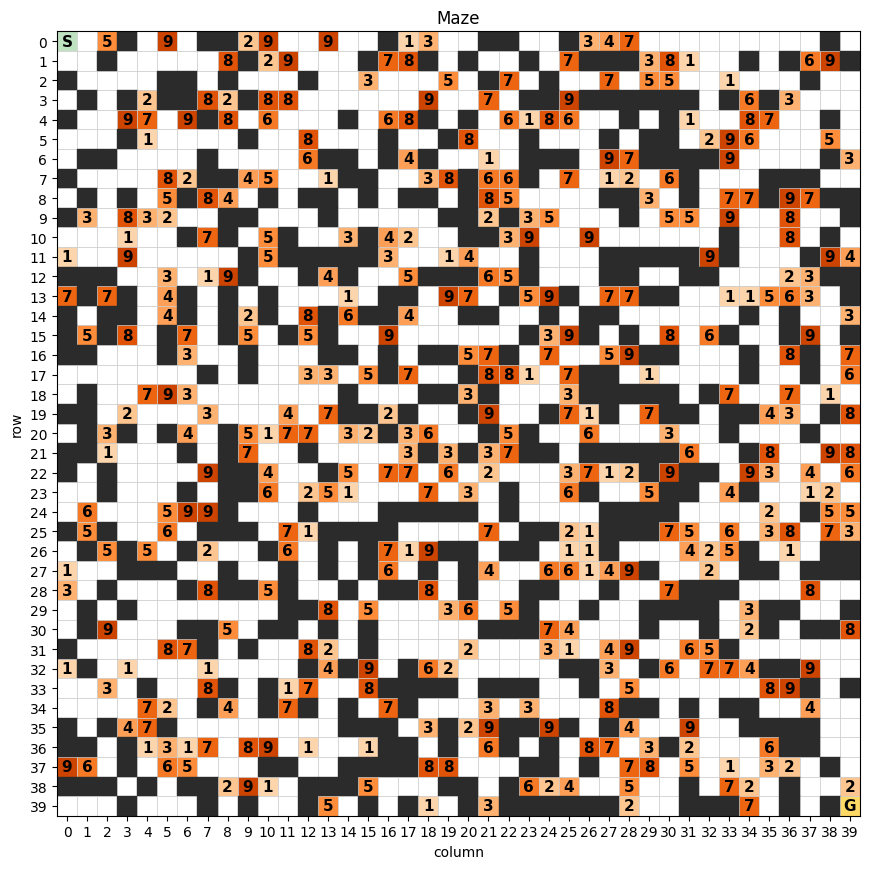

In [ ]:
import math
import random
from typing import List
from collections import deque
import matplotlib.pyplot as plt

n_rows = 40
n_cols = 40
n_cells = n_rows * n_cols
percent_wall = 0.3
n_walls = math.floor(percent_wall * n_cells)
percent_d = 0.25  # percent of the cells that have nonzero d
assert percent_wall + percent_d < 1.0
n_d = math.floor(percent_d * n_cells)

# (row, col) of start and goal squares
S = (0,0)
G = (n_rows-1, n_cols-1)

def generate_maze():
  # generate random wall squares
  walls = []
  for n_wall in range(n_walls):
    while True:
      r = random.randint(0, n_rows-1)
      c = random.randint(0, n_cols-1)
      if (r, c) != S and (r, c) != G and (r, c) not in walls:
          walls.append((r,c))
          break

  # generate random danger cells d(x)
  d_cells = {}
  for i in range(n_d):
    while True:
      r = random.randint(0, n_rows-1)
      c = random.randint(0, n_cols-1)
      if (r, c) != S and (r, c) != G and (r, c) not in walls and (r, c) not in d_cells:
        d_cells[(r, c)] = random.randint(1, 9) # danger cost between 1 and 9
        break

  MAZE = []
  for r in range(n_rows):
    row = ""
    for c in range(n_cols):
      if (r, c) in walls:
        row += "#"
      elif (r, c) == S:
        row += "S"
      elif (r, c) == G:
        row += "G"
      elif (r, c) in d_cells:
        row += str(d_cells[(r, c)])
      else:
        row += "."
    MAZE.append(row)
  return MAZE


def is_feasible_maze(maze: List[str]):
  n_r, n_c = len(maze), len(maze[0])
  seen = {S}
  queue = deque([(0, 0)])
  while queue:
    r, c = queue.popleft()
    if (r, c) == G:
      return True
    for dr, dc in [(-1, 0), (0, 1), (1, 0), (0, -1)]:
      nr, nc = r + dr, c + dc
      if 0 <= nr < n_r and 0 <= nc < n_c and maze[nr][nc] != "#" and (nr, nc) not in seen:
        seen.add((nr, nc))
        queue.append((nr, nc))
  return False

def draw_maze(values=None, policy=None, route=None, ax=None, title=None):
  # values: optional array of length len(X), e.g. J_star[0]; colors each free square
  # policy: optional array of length len(X), e.g. pi_star[0]; draws each input as an arrow
  # route:  optional list of (row, col) squares; drawn as a line
  ax = ax or plt.subplots(figsize=(8, 6))[1]
  if values is not None:
      img = np.full((n_rows, n_cols), np.nan)
      for x in X:
          img[x] = values[STATE_TO_IDX[x]]
      im = ax.imshow(img, cmap="viridis", vmin=0)
      plt.colorbar(im, ax=ax, fraction=0.035, pad=0.03, label="cost-to-go")
  for r in range(n_rows):
      for c in range(n_cols):
          ch = MAZE[r][c]
          if ch == "#":
              ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, color="#2b2b2b"))
              continue
          if values is None:
              fc = {"S": "#bfe3c0", "G": "#ffd966"}.get(ch, "white")
              if ch.isdigit():
                  fc = plt.cm.Oranges(0.15 + 0.07 * int(ch))
              ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, fc=fc, ec="#cccccc", lw=.5))
          if ch != ".":
              if values is None:
                  ax.text(c, r, ch, ha="center", va="center", fontsize=11, fontweight="bold", zorder=5)
              else:
                  ax.text(c - .42, r - .42, ch, ha="left", va="top", fontsize=8, fontweight="bold", color="white", zorder=5)
  if policy is not None:
      for x in X:
          if x == G:
              continue
          r, c = x
          dr, dc = DELTA[policy[STATE_TO_IDX[x]]]
          ax.arrow(c - .22 * dc, r - .22 * dr, .3 * dc, .3 * dr, head_width=.18,
                    length_includes_head=True, color="red", zorder=4)
  if route is not None:
      ax.plot([c for r, c in route], [r for r, c in route], "-", color="#d62728" if policy is None else "white",
              lw=3, alpha=.65, zorder=3)
  ax.set_xlim(-.5, n_cols - .5); ax.set_ylim(n_rows - .5, -.5)
  ax.set_xticks(range(n_cols)); ax.set_yticks(range(n_rows))
  ax.set_xlabel("column"); ax.set_ylabel("row")
  ax.set_title(title or "")
  return ax

# generate a random feasilbe maze
feasible_maze = False
while not feasible_maze:
  MAZE = generate_maze()
  feasible_maze = is_feasible_maze(MAZE)

# plot the random feasible maze
fig, axes = plt.subplots(1, 1, figsize=(5.5*n_cols/25, 5.5*n_rows/25))
draw_maze(ax=axes, title="Maze")
plt.tight_layout()
plt.show()

The `MAZE` variable created by `generate_maze` stores the maze representation as a list of strings, with each element of the list representing a row. Each square is represented by a single character in the string, where `#` denotes a wall, `S` denotes the start, `G` the goal, `.` represents a square where $d(x) = 0$, and a string of an integer number between 1 to 9 (inclusive, e.g. `str(9)`) represents a nonzero $d(x)$ associated with that square.

Run the following code to understand what the `MAZE` variable looks like. You will be using the variable `MAZE` as you write code for this problem.

In [ ]:
# '#' wall   '.' free   'S' start   'G' goal   '1'-'9' danger value d(x)
for row in MAZE:
  print(row) # each row is a string

S##8..57.3.94....1##2....##.1..#5###.#.#
5....59.#....#..2.....##9#3#3##.#.2...71
#5#...33.6#1.5###6.#2..#...#5#.5..5.6...
.#8674..#267#.....#2##..#8....#82.#####.
##..#1#337.6##2..#..###22#.#...###..#...
4#.5#.##5##1...#1.#..1.......#..4....74.
.#6.3.#..###...##5#.##...####.1.161#5#..
.###5#.#.19.###.4##.728.#..##..44#8.5##.
7.#.###7#2.1.391.#..#.#9.###.24..#......
...4.##.9.###..#....###2.1.#.3..1.#..3.#
#7#..#2##3.5...33.2.#6..#22....###.#9#..
9..6###.2.7#5##6#2...#...####.13#.#.##9#
2.#46..54#3#.488#.1#.85#9.###89.1..19.#7
.#2.#.###..9#956.###.7..9#6....###.8.#52
##3....239#.4.#.8....169..####8.##..5.##
###..#9#..##9#.#.......#4.####.##...53.#
.#.5###.##..##2..........#.6#...1.7....#
.....2#.##.8#1.....##1#5.68.#...3.##.#..
.##.75.53...###.####..#...#.2.#8###.#...
.92##.##.#3.##..35..6...#.58.5#.4##..##.
.2..##9#1#.7.#.#.#..##9.9...2...6.7##4#9
5.##....9.#####.##.6..#.2##8.1#.#1#5.#68
.#4.99###8#4#....4.5....#.3##.#657##.#4.
#.6..#2...6...1....#..#..7#..#...2#5##.#
5...##..7.#4.8..

The state of the agent at time step $k$ is the square it occupies, $x_k = (r_k, c_k)$ for (row, column). Let $X$ denote the set of free (non-wall) squares. The start is $\mathbf{S} = (0, 0)$ and the goal is $\mathbf{G} = (n_{\text{rows}}-1, n_{\text{cols}}-1)$. At each step $k$ the agent chooses an input $$u_k \in \{O, N, E, S, W\}$$ with displacements in (row, column) form: $O = (0,0)$, $N = (-1, 0)$, $E = (0, 1)$, $S = (1, 0)$, $W = (0, -1)$. If the agent applies an action that would drive it into a wall, the agent stays where it is (and still pays for the move):

\begin{equation}
x_{k+1} = f(x_k, u_k) = \begin{cases}
x_k + u_k, & x_k + u_k \in X \\
x_k, & x_k + u_k \notin X
\end{cases}
\end{equation}

Every input incurs a cost of $1$. We can then write the stage cost $q(x_k,u_k)$ for our optimal control task as follows:

\begin{equation}
q(x_k, u_k) = \begin{cases} 1 + d(x_k), & x_k \neq \mathbf{G} \\
0, & x_k = \mathbf{G}. \end{cases}
\end{equation}

If the robot has not reached the goal **G** at the end of the task horizon $T=150$, we incur a high penalty (sad). We express this through a terminal cost function:

\begin{equation}
P(x_T) = \begin{cases} 1000, & x_T \neq \mathbf{G} \\ 0, & x_T = \mathbf{G}. \end{cases}
\end{equation}

The optimal control problem is then

\begin{align*}
\min_{\pi_0, \dots, \pi_{T-1}} ~&~ \sum_{k=0}^{T-1} q(x_k, u_k) + P(x_T) \\
\text{subject to} ~&~ x_{k+1} = f(x_k, u_k), ~~~k = 0, 1, \dots, T-1 \\
&~ u_k = \pi_k(x_k),~~~k=0, 1, \dots, T-1\\
&~ x_0 = \mathbf{S}.
\end{align*}

**Part (a)**

In this part you will write three functions to implement the dynamics, terminal cost, and stage cost.

*   Write the function `f`, which returns the next state $x_{k+1} = f(x_k, u_k)$ as a (row, col) tuple given the current state (as a (row, col) tuple) and input (as a string of the cardinal direction, e.g. `'N'`).
*   Write the function `terminal_cost` which returns the terminal cost for a given state, $P(x)$. (Again, the state coded as a (row, col) tuple)
*  Write the function `q` which returns the stage cost $q(x_k,u_k)$. Follow the same coding conventions for the state and input going forward (tuple and string respectively).

Confirm that the assertions at the bottom of the cell pass.


You may make use of the following pre-defined dictionaries:

*   The dictionary `DELTA` contains keys corresponding to the cardinal direction strings (e.g. `'N'` for north) and values that are the corresponding displacement in (row, col) format.
*   The dictionary `d` stores values $d(x)$
*  The dictionary `STATE_TO_IDX` converts from (row, col) to the index of the state in `X`. The dictionary `IDX_TO_STATE` converts from the index of the state in `X` to the (row, col) location in the maze.



In [ ]:
from typing import Tuple

# state space X: list of tuples containing all free spaces (row, col):
X = []
for r in range(n_rows):
    for c in range(n_cols):
        if MAZE[r][c] != "#":
            X.append((r, c))

# state (row, col) to index dict
STATE_TO_IDX = {x: i for i, x in enumerate(X)}

# index to state (row, col) dict
IDX_TO_STATE = {i: x for i, x in enumerate(X)}

# d(x) over the maze -> a dictionary with keys (row, col) and values of the danger value
d = {}
for r in range(n_rows):
    for c in range(n_cols):
        if MAZE[r][c].isdigit():
            d[(r, c)] = float(MAZE[r][c])
        else:
            d[(r, c)] = 0.0

# possible inputs
INPUTS = ["O", "N", "E", "S", "W"]
DELTA   = {"O": (0, 0), "N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}  # displacements (row, col) associated with each input

# parameters
T = 150
P_term = 1000  # terminal penalty for not reaching G in T steps

def f(x: Tuple, u: str):
  # function returns the next (row, col) when action u is applied to an maze location x=(row, col)

  ##############################################
  ## Your code goes here #######################
  ##############################################

  return next_x

def terminal_cost(x: Tuple):
  # function returns the (scalar) terminal cost at a particular state x = (row, col)

  ##############################################
  ## Your code goes here #######################
  ##############################################

  return term_cost

def q(x: Tuple, u: str):
  # function returns the (scalar) stage cost associated with a state x = (row, col) and action u

  ##############################################
  ## Your code goes here #######################
  ##############################################

  return stage_cost


############################################## Code checks
# make sure the following assertions pass:
# assertions for the dynamics
assert f(S, "N") == S

# assertions for terminal cost function
while True:
  test_state = random.choice(X)
  if test_state != G:
    break
assert terminal_cost(test_state) == P_term
assert terminal_cost(G) == 0.0

# assertions for the stage cost
if MAZE[0][1] != '#':
  assert q((0, 0), "E") == 1
if MAZE[1][0] != '#':
  assert q((0, 0), "S") == 1
while True:
  test_state = random.choice(X)
  if d[test_state] != 0:
    for u in INPUTS:
      assert q(test_state, u) == 1.0 + d[test_state]
    break
assert q(G, "N") == 0

# if the following prints out -> you made it! continue onto the next part!
print("Assertions passed!")

Assertions passed!


**Part (b)**

Write and implement the function `backward_dp_pr5`, using the dynamic programming algorithm and your functions from part (a). The function should return:

* `J_star`: an array of shape `(T+1, len(X))` with `J_star[k, STATE_TO_IDX[x]]` $= J_k^*(x)$,
* `pi_star`: an array of shape `(T, len(X))` with `pi_star[k, STATE_TO_IDX[x]]` $= \pi_k^*(x)$, stored as the letter `'O'`, `'N'`, `'E'`, `'S'` or `'W'`.


Return the output of the print statement at the bottom of the cell.

In [ ]:
import numpy as np

def backward_dp_pr5():
  # function returns arrays of the optimal cost-to-go and policy for all possible states at all possible k

  ##############################################
  ## Your code goes here #######################
  ##############################################

  return J_star, pi_star

# return the output of the following test
J_star, pi_star = backward_dp_pr5()
print(f'J_0^*(S) = {J_star[0, STATE_TO_IDX[(0,0)]]}')

NameError: name 'J_star' is not defined

Once you have written the dynamic programming function above, the code below uses `J_star` and `pi_star` to simulate the agent from the initial state $\mathbf{S} = (0,0)$ under the closed-loop policy through the maze. Run the following code to get the length of the path and the closed-loop cost, and a plot which illustrates the resulting path through the maze.

Trajectory length: 151
Cost: 160.0


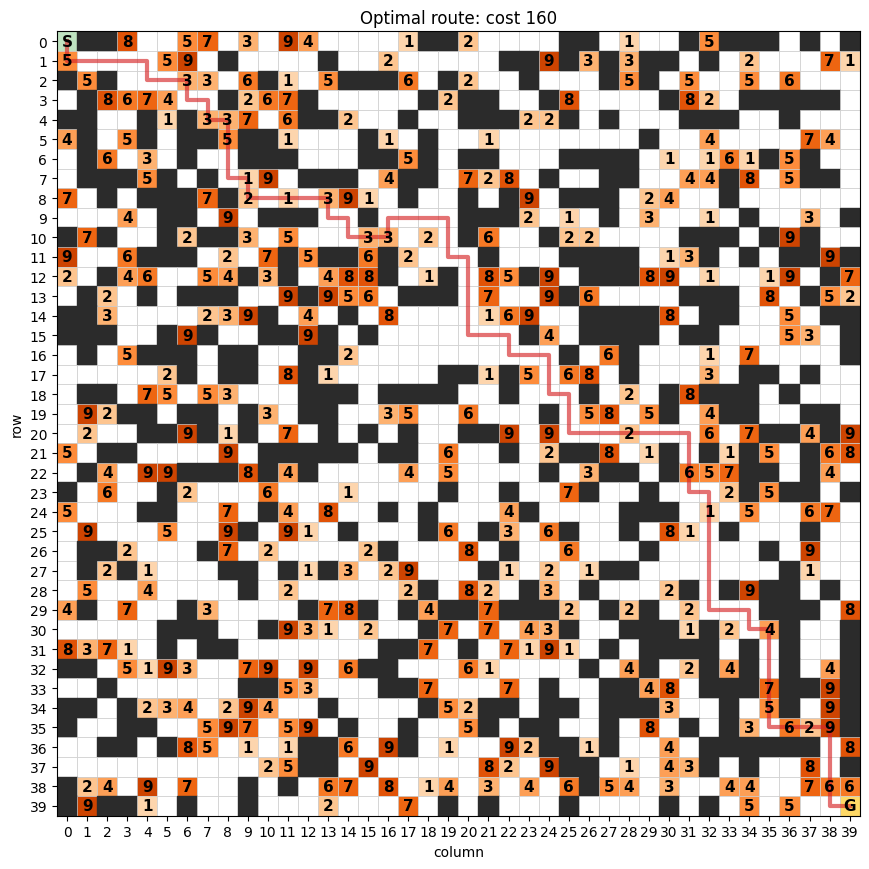

In [ ]:
x_traj = [S]
u_traj = []
cost = 0
xk = x_traj[-1]
k = 0

while k < T:
  uk = pi_star[k, STATE_TO_IDX[xk]]
  xkp1 = f(xk, uk)
  x_traj.append(xkp1)
  u_traj.append(uk)
  cost += q(xk, uk)
  xk = xkp1
  k += 1
if k == T:
  cost += terminal_cost(xk)

print(f'Trajectory length: {len(x_traj)}')
print(f'Cost: {cost}')

fig, axes = plt.subplots(1, 1, figsize=(5.5*n_cols/25, 5.5*n_rows/25))
draw_maze(route=x_traj, ax=axes, title=f"Optimal route: cost {cost:.0f}")
plt.tight_layout()
plt.show()

**Part (c):**

Answer the following questions:

1.   What is the relationship between $J_0^*(S)$ and the realized closed-loop cost? (The realized closed-loop cost is printed in the prior part.)
2.   Would an open-loop batch solution where $u_0, \dots, u_{T-1}$ are chosen at $k=0$ give you the same route and cost as the closed-loop policy in this problem? Why or why not?
3.   Suppose the robot instead starts at some other free square $x_0 \neq \mathbf{S}$. How would you find the optimal policy from the initial state $x_0$?

